# **Random Forest**

In [134]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [135]:
data = pd.read_csv(r"C:\Users\LENOVO\Desktop\ML practice\heart_disease.csv")

In [136]:
data.head()

,Age,Gender,Blood Pressure,Cholesterol Level,Exercise Habits,Smoking,Family Heart Disease,Diabetes,BMI,High Blood Pressure,...,High LDL Cholesterol,Alcohol Consumption,Stress Level,Sleep Hours,Sugar Consumption,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level,Heart Disease Status
0,56.0,Male,153.0,155.0,High,Yes,Yes,No,24.991591,Yes,...,No,High,Medium,7.633228,Medium,342.0,NaN,12.969246,12.387250,No
1,69.0,Female,146.0,286.0,High,No,Yes,Yes,25.221799,No,...,No,Medium,High,8.744034,Medium,133.0,157.0,9.355389,19.298875,No
2,46.0,Male,126.0,216.0,Low,No,No,No,29.855447,No,...,Yes,Low,Low,4.440440,Low,393.0,92.0,12.709873,11.230926,No
3,32.0,Female,122.0,293.0,High,Yes,Yes,No,24.130477,Yes,...,Yes,Low,High,5.249405,High,293.0,94.0,12.509046,5.961958,No
4,60.0,Male,166.0,242.0,Low,Yes,Yes,Yes,20.486289,Yes,...,No,Low,High,7.030971,High,263.0,154.0,10.381259,8.153887,No


In [137]:
data.shape

(10000, 21)

In [138]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Age                   9971 non-null   float64
 1   Gender                9981 non-null   str    
 2   Blood Pressure        9981 non-null   float64
 3   Cholesterol Level     9970 non-null   float64
 4   Exercise Habits       9975 non-null   str    
 5   Smoking               9975 non-null   str    
 6   Family Heart Disease  9979 non-null   str    
 7   Diabetes              9970 non-null   str    
 8   BMI                   9978 non-null   float64
 9   High Blood Pressure   9974 non-null   str    
 10  Low HDL Cholesterol   9975 non-null   str    
 11  High LDL Cholesterol  9974 non-null   str    
 12  Alcohol Consumption   7414 non-null   str    
 13  Stress Level          9978 non-null   str    
 14  Sleep Hours           9975 non-null   float64
 15  Sugar Consumption     9970 non-

In [139]:
data.isna().mean()*100

Age                      0.29
Gender                   0.19
Blood Pressure           0.19
Cholesterol Level        0.30
Exercise Habits          0.25
Smoking                  0.25
Family Heart Disease     0.21
Diabetes                 0.30
BMI                      0.22
High Blood Pressure      0.26
Low HDL Cholesterol      0.25
High LDL Cholesterol     0.26
Alcohol Consumption     25.86
Stress Level             0.22
Sleep Hours              0.25
Sugar Consumption        0.30
Triglyceride Level       0.26
Fasting Blood Sugar      0.22
CRP Level                0.26
Homocysteine Level       0.20
Heart Disease Status     0.00
dtype: float64

In [140]:
data.duplicated().sum()

np.int64(0)

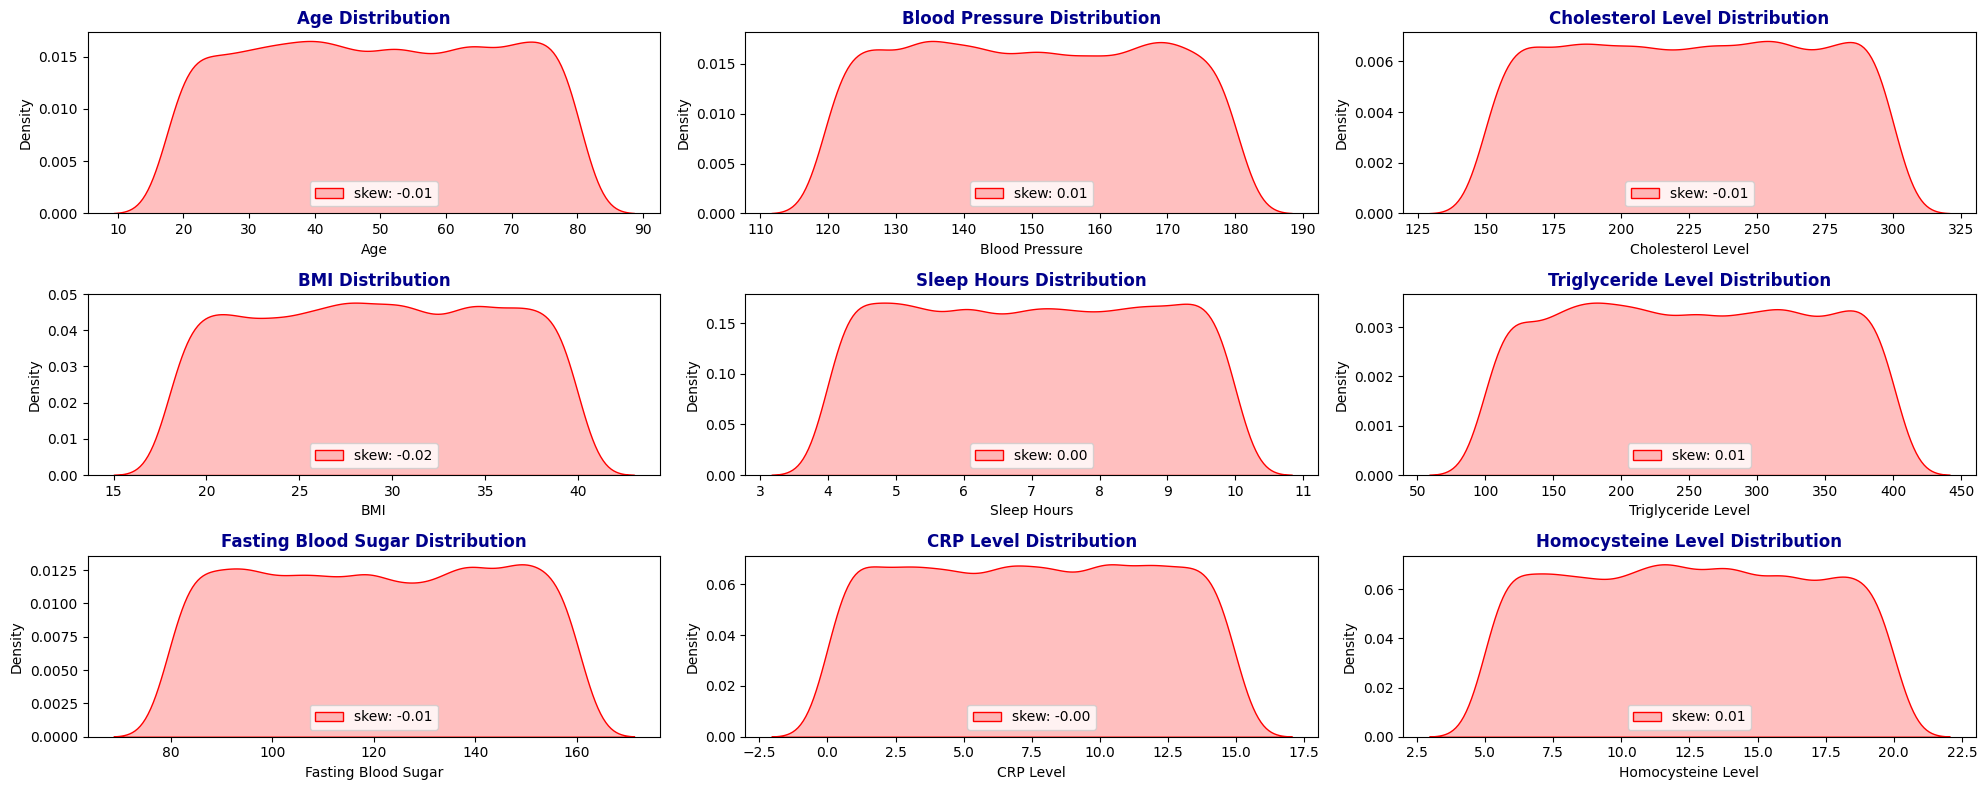

In [141]:
num_cols = data.select_dtypes(include='number').columns.to_list()
fig , axes = plt.subplots(3,3,figsize = (20,8))
axes = axes.flatten()
for i,col in enumerate(num_cols):
    sns.kdeplot(data[col],fill=True,ax=axes[i],label = f'skew: {data[col].skew():.2f}',color='red')
    axes[i].set_title(f"{col} Distribution",fontweight ='bold',color='darkblue')
    axes[i].set_xlabel(col)
    axes[i].legend()
plt.tight_layout()

In [158]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline as skPipeline
from sklearn.preprocessing import OneHotEncoder,OrdinalEncoder,LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix,precision_recall_curve
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

In [143]:
x = data.iloc[:,:-1]
y = data.iloc[:,-1]

In [144]:
cat_cols = x.select_dtypes(include='str').columns.to_list()

In [145]:
le = LabelEncoder()
y = le.fit_transform(y)

In [146]:
x_train , x_test , y_train , y_test =  train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

In [147]:
pd.crosstab(data['Gender'],data['Heart Disease Status'],normalize='index')*100

Heart Disease Status,No,Yes
Gender,,
Female,79.308959,20.691041
Male,80.631621,19.368379


In [148]:
cat_cols1 = x.select_dtypes(include='str').columns.to_list()
cat_cols1.remove('Gender')

In [149]:
data['Heart Disease Status'].value_counts()

Heart Disease Status
No     8000
Yes    2000
Name: count, dtype: int64

- Imbalance data , required over-smapling technique(SMOTE)


In [166]:
preprocessor = ColumnTransformer(transformers=[
    ('num_impute', SimpleImputer(strategy='mean'), num_cols),
    ('oe', skPipeline(steps=[
        ('cat_impute', SimpleImputer(strategy='most_frequent')),
        ('ordinal', OrdinalEncoder(
            categories=[
                ['Femle','Male'],
                ['Low', 'Medium', 'High'],
                ['Yes', 'No'],
                ['Yes', 'No'],
                ['Yes', 'No'],
                ['Yes', 'No'],
                ['Yes', 'No'],
                ['Yes', 'No'],
                ['Low', 'Medium', 'High'],
                ['Low', 'Medium', 'High'],
                ['Low', 'Medium', 'High']
            ],
            handle_unknown='use_encoded_value',
            unknown_value=-1
        ))
    ]), cat_cols1)
])

In [167]:
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight=None,
        n_jobs=-1
    ))
])

In [168]:
pipeline.fit(x_train,y_train)

ValueError: Shape mismatch: if categories is an array, it has to be of shape (n_features,).